In [1]:
import gym
import logging
import json
from pathlib import Path
from time import monotonic
import crafter
import torch.nn as nn
import matplotlib as plt
import torch
import random
from collections import deque
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import os
from functools import reduce
import matplotlib.pyplot as plt
import numpy as np

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [ ]:
# CNN arguments
height = 64
width = 64
channels_in = 3
channels_hidden_1 = 32
channels_hidden_2 = 64
channels_hidden_3 = 128
channels_hidden_4 = 256
hidden_size_cnn = 1024
kernel_size = 4
stride = 2
padding = 1
dilation = 1
groups = 1

# LSTM arguments
num_layers_lstm = 2
hidden_size_lstm = 1024

# ActorCritic architecture arguments(and training)
hidden_size_input = hidden_size_lstm
num_actions = 17
actor_critic_lr = 0.0003
centered = False
alpha = 0.99
eps_optim = 1e-8
game_batch = 64
actor_loss_weight = 1.0
critic_loss_weight = 0.5
entropy_loss_weight = 0.1

# discount for greediness
discount_greediness = 0.9978

# after how many steps should update
# steps_updating = 2000
steps_updating = 1

# experiences every iteration
num_exp = 16

# total iterations
iterations = 5000

# contrastive loss arguments
warm_up_steps = 512
prob_contrastive = 0.2
contrastive_loss_batch_size = 64
contrastive_loss_temperature = 1.1
lr_contrastive_learning = 1e-4
weight_decay = True
contrastive_sim_weight = 1.0
contrastive_near_loss_weight = 0.2

# crafter
seq_length = 20

# RL
discount = 0.9985

In [3]:
class CNNEncoder(nn.Module):
    def __init__(self, h, w, c, c1 = 32, c2 = 64, c3 = 128, c4 = 256, hidden_size = 1024, kernel_size = 4, stride = 2, padding = 1, dilation = 1, groups = 1):
        super().__init__()
        h1o = int(((h + 2 * padding - kernel_size) / stride) + 1)
        h2o = int(((h1o + 2 * padding - kernel_size) / stride) + 1)
        h3o = int(((h2o + 2 * padding - kernel_size) / stride) + 1)
        h4o = int(((h3o + 2 * padding - kernel_size) / stride) + 1)

        w1o = int(((w + 2 * padding - kernel_size) / stride) + 1)
        w2o = int(((w1o + 2 * padding - kernel_size) / stride) + 1)
        w3o = int(((w2o + 2 * padding - kernel_size) / stride) + 1)
        w4o = int(((w3o + 2 * padding - kernel_size) / stride) + 1)
        self.net = nn.Sequential(
            nn.Conv2d(c, c1, kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups),
            nn.ELU(),
            nn.Conv2d(c1, c2, kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups),
            nn.ELU(),
            nn.Conv2d(c2, c3, kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups),
            nn.ELU(),
            nn.Conv2d(c3, c4, kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups),
            nn.ELU(),
            nn.Flatten(),
            nn.Linear(c4 * h4o * w4o, hidden_size)
        )

    def forward(self, x):
        return self.net(x)

In [4]:
class LatentStateEncoder(nn.Module):
    def __init__(self, h, w, c, num_layers = 2, hidden_size_lstm = 1024, c1 = 32, c2 = 64, c3 = 128, c4 = 256, hidden_size_cnn = 1024, kernel_size = 4, stride = 2, padding = 1, dilation = 1, groups = 1):
        super().__init__()
        self.input_size_lstm = hidden_size_cnn
        self.visual_encoder = CNNEncoder(h, w, c, c1, c2, c3, c4, hidden_size_cnn, kernel_size, stride, padding, dilation)
        self.lstm = nn.LSTM(hidden_size_cnn, hidden_size_lstm, num_layers=num_layers, batch_first=True)
    
    def forward(self, x):
        if len(x.shape) != 5:
            return None
        batch, seq_length, channels, h, w = x.shape
        x = x.reshape(batch * seq_length, channels, h, w)
        encoded_states = self.visual_encoder(x)
        encoded_states = encoded_states.reshape(batch, seq_length, self.input_size_lstm)
        return self.lstm(encoded_states)

In [5]:
class ActorCritic(nn.Module):
    def __init__(self, latent_space_encoder_model, num_layers, hidden_size, num_actions):
        super().__init__()
        self.num_actions = num_actions
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.lse_model = latent_space_encoder_model
        self.actor_net = nn.Sequential(
            nn.Linear(hidden_size, 2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.ReLU(),
            nn.Linear(1024, num_actions)
        )
        self.critic_net = nn.Sequential(
            nn.Linear(hidden_size, 2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.ReLU(),
            nn.Linear(1024, 1)
        )


    def forward(self, x):
        if len(x.shape) != 5:
            return None
        batch_size, seq_length, channel_size, h, w = x.shape
        # lstm_output shape ===> batch_size, seq_length, hidden_size
        lstm_output, h_c_n = self.lse_model(x)
        # h_n shape ===> num_layers, batch_size, hidden_size
        # c_n shape ===> num_layers, batch_size, hidden_size
        h_n, c_n = h_c_n
        last_output = lstm_output[:, -1, :]
        return self.actor_net(last_output), self.critic_net(last_output), last_output, lstm_output, h_n, c_n

In [6]:
def take_action(model, state, num_actions):
    logits, value, last_lstm_out, lstm_out, h_n, c_n = model(state)
    dist = torch.distributions.Categorical(logits=logits[0])
    action = dist.sample()
    return action.item()

In [7]:
env = crafter.Env(seed=42)
env = crafter.Recorder(
    env,
    "../logs",
    save_stats=True,
    save_video=False,
    save_episode=False,
)
obs = env.reset()

In [8]:
achievement_list = [
    'collect_coal', 'collect_diamond', 'collect_drink', 'collect_iron',
    'collect_sapling', 'collect_stone', 'collect_wood', 'defeat_skeleton',
    'defeat_zombie', 'eat_cow', 'eat_plant', 'make_iron_pickaxe',
    'make_iron_sword', 'make_stone_pickaxe', 'make_stone_sword', 'make_wood_pickaxe',
    'make_wood_sword', 'place_furnace', 'place_plant', 'place_stone',
    'place_table', 'wake_up'
]

In [9]:
achievement_dict = {ach: index for ach, index in zip(achievement_list, range(len(achievement_list)))}

achievement_inverse_dict = {index: ach for ach, index in achievement_dict.items()}

In [10]:
def play_and_store(
    model, env, seq_length,
    c, h, w, hidden_size,
    achievement_dict,
    device, num_actions
    ):
    with torch.no_grad():
        er_buffer_obs = torch.empty(0, seq_length, c, h, w).to(device)
        er_buffer_f_obs = torch.empty(0, seq_length, c, h, w).to(device)
        er_buffer_actions = torch.empty(0).to(device)
        er_buffer_reward = torch.empty(0).to(device)
        er_buffer_achievement = torch.empty(0, len(achievement_dict)).to(device)
        er_buffer_latent_space_obs = torch.empty(0, hidden_size).to(device)
        er_buffer_latent_space_f_obs = torch.empty(0, hidden_size).to(device)
        obs = env.reset()
        obs = torch.as_tensor(obs, dtype=torch.float32, device=device)
        obs = obs.permute(2, 0, 1) / 255.0
        tensor_obs = torch.empty(0, c, h, w).to(device)
        for i in range(seq_length + 1):
            obs_zero = torch.zeros(1, c, h, w).to(device)
            tensor_obs = torch.cat([tensor_obs, obs_zero], dim=0)
        tensor_obs = torch.cat([tensor_obs, obs.unsqueeze(0)], dim = 0)
        done = False
        past_info = {k: 0 for k, _ in achievement_dict.items()}
        while done is not True:
            action = take_action(model, tensor_obs[-seq_length :,:,:,:].unsqueeze(0), num_actions)
            obs, reward, done, info = env.step(action)
            obs = torch.as_tensor(obs, dtype=torch.float32, device=device)
            obs = obs.permute(2, 0, 1) / 255.0
            tensor_obs = torch.cat([tensor_obs, obs.unsqueeze(0)], dim = 0)
            er_buffer_obs = torch.cat([er_buffer_obs, tensor_obs[-(seq_length + 1) : -1,:,:,:].unsqueeze(0)], dim=0)
            er_buffer_f_obs = torch.cat([er_buffer_f_obs, tensor_obs[-seq_length :,:,:,:].unsqueeze(0)], dim=0)
            er_buffer_actions = torch.cat([er_buffer_actions, torch.tensor([action]).to(device)], dim=0)
            er_buffer_reward = torch.cat([er_buffer_reward, torch.tensor([reward]).to(device)], dim = 0)
            achievement_tensor = torch.zeros(len(achievement_dict)).to(device)
            for ach, obtained in info['achievements'].items():
                if obtained == 1 and past_info[ach] == 0:
                    achievement_tensor[achievement_dict[ach]] = 1.0
                    past_info[ach] = 1.0
            er_buffer_achievement = torch.cat([er_buffer_achievement, achievement_tensor.unsqueeze(0)], dim = 0)
            _, _, last_lstm_output_obs, _, _, _ = model(tensor_obs[-(seq_length + 1) : -1,:,:,:].unsqueeze(0))
            _, _, last_lstm_output_f_obs, _, _, _ = model(tensor_obs[-seq_length :,:,:,:].unsqueeze(0))
            er_buffer_latent_space_obs = torch.cat([er_buffer_latent_space_obs, last_lstm_output_obs], dim = 0)
            er_buffer_latent_space_f_obs = torch.cat([er_buffer_latent_space_f_obs, last_lstm_output_f_obs], dim = 0)
    er_buffer_done = torch.zeros(er_buffer_reward.shape[0]).to(device)
    er_buffer_done[-1] = 1.0
    return er_buffer_obs, er_buffer_f_obs, er_buffer_actions, er_buffer_reward, er_buffer_achievement, er_buffer_latent_space_obs, er_buffer_latent_space_f_obs, er_buffer_done
    


In [11]:
device = (
    torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
)
if torch.cuda.is_available():
    device = torch.device("cuda")

In [12]:
lstm_model = LatentStateEncoder(height, width, channels_in, num_layers_lstm, hidden_size_lstm,
    channels_hidden_1, channels_hidden_2, channels_hidden_3, channels_hidden_4,
    hidden_size_cnn, kernel_size, stride, padding, dilation, groups).to(device)
a2c_model = ActorCritic(lstm_model, num_layers_lstm, hidden_size_lstm, num_actions).to(device)
# er_buffer_obs, er_buffer_f_obs, er_buffer_actions, er_buffer_reward, er_buffer_achievement, er_buffer_latent_space_obs, er_buffer_latent_space_f_obs, er_done = play_and_store(a2c_model, env, seq_length, channels_in, height, width, hidden_size_lstm, achievement_dict, device, num_actions)
# print(f"{er_buffer_obs.shape}")
# print(f"{er_buffer_f_obs.shape}")
# print(f"{er_buffer_actions.shape}")
# print(f"{er_buffer_reward.shape}")
# print(f"{er_buffer_achievement.shape}")
# print(f"{er_buffer_latent_space_obs.shape}")
# print(f"{er_buffer_latent_space_f_obs.shape}")

In [13]:
def create_experiences(
    model, env, seq_length,
    c, h, w, hidden_size,
    achievement_dict, num_experiences,
    device, num_actions
):
    exp_buffer_obs = []
    exp_buffer_f_obs = []
    exp_buffer_actions = []
    exp_buffer_reward = []
    exp_buffer_achievement = []
    exp_buffer_latent_space_obs = []
    exp_buffer_latent_space_f_obs = []
    exp_buffer_done = []
    for i in range(num_experiences):
        er_buffer_obs, er_buffer_f_obs, er_buffer_actions, er_buffer_reward, er_buffer_achievement, er_buffer_latent_space_obs, er_buffer_latent_space_f_obs, er_buffer_done = play_and_store(model, env, seq_length, c, h, w, hidden_size, achievement_dict, device, num_actions)
        exp_buffer_obs.append(er_buffer_obs)
        exp_buffer_f_obs.append(er_buffer_f_obs)
        exp_buffer_actions.append(er_buffer_actions)
        exp_buffer_reward.append(er_buffer_reward)
        exp_buffer_achievement.append(er_buffer_achievement)
        exp_buffer_latent_space_obs.append(er_buffer_latent_space_obs)
        exp_buffer_latent_space_f_obs.append(er_buffer_latent_space_f_obs)
        exp_buffer_done.append(er_buffer_done)
    return exp_buffer_obs, exp_buffer_f_obs, exp_buffer_actions, exp_buffer_reward, exp_buffer_achievement, exp_buffer_latent_space_obs, exp_buffer_latent_space_f_obs, exp_buffer_done


In [14]:
def actor_loss(log_probs, advantages):
    compute_la = log_probs * advantages.detach()
    return -(compute_la.mean())

In [15]:
def critic_loss(advantages):
    return (advantages * advantages).mean()

In [16]:
def contrastive_loss(ach_episodes, temperature):
    if temperature <= 0:
        raise ValueError("Contrastive temperature must be positive")
    items = [(k, v) for k, v in ach_episodes.items() if v.shape[0] > 0]
    if len(items) < 2:
        return None

    z = F.normalize(torch.cat([v for _, v in items]), dim=1)
    labels = torch.cat([torch.full((v.shape[0],), k, device=z.device) for k, v in items])

    logits = z @ z.T / temperature
    upper = torch.ones_like(logits, dtype=torch.bool).triu(diagonal=1)   # perechi i < j
    same = labels[:, None] == labels[None, :]

    pos = logits[upper & same]
    neg = logits[upper & ~same]
    if pos.numel() == 0 or neg.numel() == 0:
        return None

    return torch.logsumexp(neg, dim=0) - pos.mean()

In [17]:
def near_loss(ach_tensor, old_ach_tensor, hidden_size, num_achievements, device):
    new_emb = torch.empty(0, hidden_size).to(device)
    old_emb = torch.empty(0, hidden_size).to(device)
    for k, v in ach_tensor.items():
        new_emb = torch.cat([new_emb, v], dim=0)
        old_emb = torch.cat([old_emb, old_ach_tensor[k]], dim=0)
    return 1 - F.cosine_similarity(new_emb, old_emb, dim=-1).mean()

In [18]:
a = torch.tensor([[0.0, 0.0, 1.0], [1.0, 0.0, 0.0], [1.0, 0.0, 0.0], [1.0, 0.0, 0.0]])
b = torch.zeros(3)
b[0] = 1.0
equalities = (a == b)
equalities


tensor([[False,  True, False],
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]])

In [19]:
torch.where(equalities.all(dim=1))

(tensor([1, 2, 3]),)

In [20]:
def train_model(
    a2c_model, lstm_model, clone_lstm, temp_clone, env,
    steps_to_play, games_per_play,
    optim_lr, centered, alpha, eps_optim,
    seq_length, c, h, w, hidden_size,
    achievement_dict, device, num_actions,
    game_batch_size, discount, actor_loss_weight,
    critic_loss_weight, entropy_loss_weight,
    prob_contrastive, warm_up_steps, contrastive_loss_batch_size,
    contrastive_loss_temperature, lr_contrastive_learning,
    weight_decay, contrastive_sim_weight, contrastive_near_loss_weight,
    output_dir=None
):
    output_dir = Path(output_dir or os.getenv("OUTPUT_DIR", "logs/sebi-notebook")).expanduser().resolve()
    output_dir.mkdir(parents=True, exist_ok=True)

    def record_metrics(metrics):
        record = json.dumps(metrics, allow_nan=False)
        with (output_dir / "metrics.jsonl").open("a", encoding="utf-8") as metrics_file:
            metrics_file.write(record + "\n")

    optimizer = torch.optim.RMSprop(
        a2c_model.parameters(), lr=optim_lr,
        centered=centered, alpha=alpha
    )

    contrastive_learning_optimizer = torch.optim.AdamW(
        lstm_model.parameters(), lr=lr_contrastive_learning,
        weight_decay=1e-2
    )

    losses_over_time = []
    contrastive_loss_over_time = []
    actor_loss_over_time = []
    critic_loss_over_time = []
    entropy_loss_over_time = []
    average_reward_over_time = []
    average_steps_over_time = []
    for play_step in range(steps_to_play):
        started = monotonic()
        with torch.no_grad():
            buffer_list_tuple = create_experiences(a2c_model, env, seq_length, c, h, w, hidden_size,
                achievement_dict, games_per_play, device, num_actions)
        average_reward_over_time.append((reduce(lambda acc, x: acc + torch.sum(x), buffer_list_tuple[3], 0) / games_per_play))
        average_steps_over_time.append((reduce(lambda acc, x: acc + x.shape[0], buffer_list_tuple[3], 0) / games_per_play))
        metrics = {
            "iteration": play_step + 1,
            "average_reward": average_reward_over_time[-1].item(),
            "average_steps": average_steps_over_time[-1],
            "achievements": {
                key: sum(ach[:, index].sum().item() for ach in buffer_list_tuple[4])
                for key, index in achievement_dict.items()
            },
        }
        # Contrastive Loss
        losses_step = []
        if play_step >= warm_up_steps:
            # aici trebuie sa vezi ca ti se intoarce lista, nu tensor
            if random.choices(population=[0, 1], weights=[1 - prob_contrastive, prob_contrastive])[0] == 1:
                # games_per_play => steps_taken, seq_length, channels, h, w
                list_tensor_obs = buffer_list_tuple[0]
                # games_per_play => steps_takes, achievement_dict_len
                list_tensor_ach = buffer_list_tuple[4]
                for start in range(0, games_per_play, contrastive_loss_batch_size):
                    stop = min(start + contrastive_loss_batch_size, games_per_play)
                    ach_episodes = {idx: torch.empty([0, seq_length, c, h, w]).to(device) for idx in range(len(achievement_dict))}
                    for ach_idx in range(len(achievement_dict)):
                        for k in range(start, stop):
                            tensor_obs = list_tensor_obs[k]
                            tensor_ach = list_tensor_ach[k]
                            indices = torch.where(tensor_ach[:, ach_idx] > 0)[0]
                            ach_episodes[ach_idx] = torch.cat([ach_episodes[ach_idx], tensor_obs[indices, :, :, :, :]], dim=0)
                    contrastive_learning_optimizer.zero_grad()
                    temp_clone.load_state_dict(lstm_model.state_dict())
                    ach_tensor = {}
                    old_ach_tensor = {}
                    for key, val in ach_episodes.items():
                        if val.shape[0] < 1.0:
                            continue
                        ach_obs, _ = lstm_model(val)
                        with torch.no_grad():
                            old_ach_obs, _ = clone_lstm(val)
                            old_ach_tensor[key] = old_ach_obs[:, -1, :]
                        ach_tensor[key] = ach_obs[:, -1, :]
                    if len(ach_tensor) == 0:
                        logging.warning("Skipping contrastive games %s:%s: no achievements", start, stop)
                        continue
                    contrastive_loss_value = contrastive_loss(ach_tensor, contrastive_loss_temperature)
                    loss = contrastive_near_loss_weight * near_loss(ach_tensor, old_ach_tensor, hidden_size, len(achievement_dict), device)
                    if contrastive_loss_value is None:
                        logging.warning("Games %s:%s: insufficient contrastive pairs; near loss only", start, stop)
                    else:
                        loss = loss + contrastive_sim_weight * contrastive_loss_value
                    if not torch.isfinite(loss).item():
                        raise RuntimeError("Non-finite contrastive loss")
                    loss.backward()
                    losses_step.append(loss.item())
                    contrastive_learning_optimizer.step()
                    clone_lstm.load_state_dict(temp_clone.state_dict())
                if len(losses_step) > 0:
                    contrastive_loss_over_time.append((sum(losses_step) / len(losses_step)))
                metrics.update({
                    "mode": "contrastive",
                    "contrastive_updates": len(losses_step),
                    "contrastive_loss": sum(losses_step) / len(losses_step) if losses_step else None,
                    "seconds": monotonic() - started,
                })
                record_metrics(metrics)
                continue
        
        # Actor-Critic part
        losses_step = []
        a_losses_step = []
        c_losses_step = []
        e_losses_step = []
        diagnostic_sums = {"advantages_abs_mean": 0.0, "value_abs_mean": 0.0, "reward_abs_mean": 0.0}
        transition_count = 0
        for game in range(games_per_play):
            len_steps = buffer_list_tuple[0][game].shape[0]
            indices = torch.randperm(len_steps)
            tensor_obs = buffer_list_tuple[0][game][indices]
            tensor_f_obs = buffer_list_tuple[1][game][indices]
            tensor_act = buffer_list_tuple[2][game][indices]
            tensor_reward = buffer_list_tuple[3][game][indices]
            tensor_ach = buffer_list_tuple[4][game][indices]
            tensor_latent = buffer_list_tuple[5][game][indices]
            tensor_f_latent = buffer_list_tuple[6][game][indices]
            tensor_er_done = buffer_list_tuple[7][game][indices]
            for i in range(0, len_steps, game_batch_size):
                optimizer.zero_grad()
                actor_output, critic_output, last_output, lstm_output, h_n, c_n = a2c_model(tensor_obs[i: min(game_batch_size + i, len_steps)])
                _, critic_output_f_state, _, _, _, _ = a2c_model(tensor_f_obs[i: min(game_batch_size + i, len_steps)])
                critic_output = critic_output.squeeze(-1)
                critic_output_f_state = critic_output_f_state.squeeze(-1)
                with torch.no_grad():
                    # adauga aici si done din tensor nou ca sa anulam ce este terminat
                    target = (tensor_reward[i: min(game_batch_size + i, len_steps)] + discount * (1 - tensor_er_done[i: min(game_batch_size + i, len_steps)]) * critic_output_f_state)
                advantages = target - critic_output
                distributions = torch.distributions.Categorical(logits=actor_output)
                log_probs = distributions.log_prob(tensor_act[i: min(game_batch_size + i, len_steps)])
                a_loss = actor_loss(log_probs, advantages)
                c_loss = critic_loss(advantages)
                e_loss = -(distributions.entropy().mean())
                loss = actor_loss_weight * a_loss + critic_loss_weight * c_loss - entropy_loss_weight * distributions.entropy().mean()
                # print(
                #     "reward_abs:", tensor_reward[i:i + game_batch_size].abs().mean().item(),
                #     "adv_abs:", advantages.abs().mean().item(),
                #     "V_abs:", critic_output.abs().mean().item(),
                #     "entropy:", distributions.entropy().mean().item(),
                # )
                diagnostic_sums["advantages_abs_mean"] += advantages.detach().abs().sum().item()
                diagnostic_sums["value_abs_mean"] += critic_output.detach().abs().sum().item()
                diagnostic_sums["reward_abs_mean"] += tensor_reward[i:i + game_batch_size].abs().sum().item()
                transition_count += advantages.numel()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(a2c_model.parameters(), 0.5)
                optimizer.step()
                losses_step.append(loss.item())
                a_losses_step.append(a_loss.item())
                c_losses_step.append(c_loss.item())
                e_losses_step.append(e_loss.item())
        avg_loss_step = sum(losses_step) / len(losses_step)
        losses_over_time.append(avg_loss_step)
        actor_loss_over_time.append(sum(a_losses_step) / len(a_losses_step))
        critic_loss_over_time.append(sum(c_losses_step) / len(c_losses_step))
        entropy_loss_over_time.append(sum(e_losses_step) / len(e_losses_step))
        metrics.update({
            "mode": "actor_critic",
            "loss": losses_over_time[-1],
            "actor_loss": actor_loss_over_time[-1],
            "critic_loss": critic_loss_over_time[-1],
            "entropy": -entropy_loss_over_time[-1],
            "seconds": monotonic() - started,
        })
        metrics.update({key: total / transition_count for key, total in diagnostic_sums.items()})
        record_metrics(metrics)
    return a2c_model, lstm_model, losses_over_time, actor_loss_over_time, critic_loss_over_time, entropy_loss_over_time, contrastive_loss_over_time, average_reward_over_time, average_steps_over_time

In [21]:
def plot_metrics(output_dir):
    from IPython.display import Image, display
    if Path("contrastive_actor_critic.py").is_file():
        from contrastive_actor_critic import save_plots
    else:
        from src.sebi.contrastive_actor_critic import save_plots

    output_dir = Path(output_dir).expanduser().resolve()
    save_plots(output_dir)
    for image_path in sorted((output_dir / "plots").glob("*.png")):
        display(Image(filename=str(image_path)))

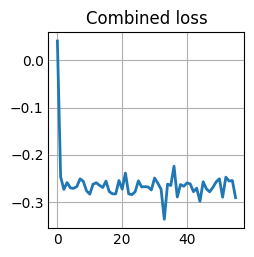

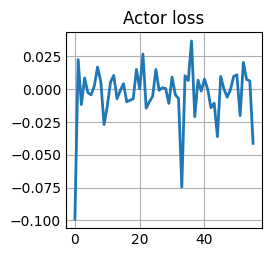

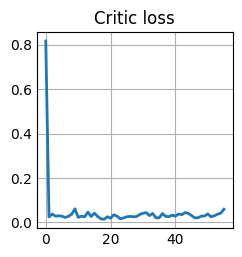

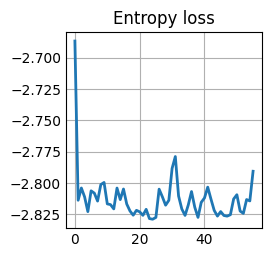

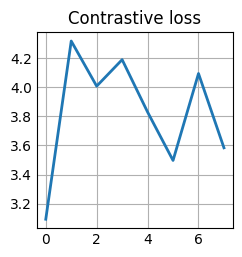

In [22]:
notebook_output_dir = Path(os.getenv("OUTPUT_DIR", "logs/sebi-notebook")).expanduser().resolve()
clone_lstm_model = LatentStateEncoder(height, width, channels_in, num_layers_lstm, hidden_size_lstm,
    channels_hidden_1, channels_hidden_2, channels_hidden_3, channels_hidden_4,
    hidden_size_cnn, kernel_size, stride, padding, dilation, groups).to(device)
temp_lstm_model = LatentStateEncoder(height, width, channels_in, num_layers_lstm, hidden_size_lstm,
    channels_hidden_1, channels_hidden_2, channels_hidden_3, channels_hidden_4,
    hidden_size_cnn, kernel_size, stride, padding, dilation, groups).to(device)
clone_lstm_model.load_state_dict(lstm_model.state_dict())
temp_lstm_model.load_state_dict(lstm_model.state_dict())
a2c_model, lstm_model, losses_over_time, actor_loss_over_time, critic_loss_over_time, entropy_loss_over_time, contrastive_loss_over_time, average_reward_over_time, average_steps_over_time = train_model(a2c_model, lstm_model, clone_lstm_model, temp_lstm_model, env, iterations, num_exp, actor_critic_lr,
    centered, alpha, eps_optim, seq_length, channels_in, height, width, hidden_size_lstm, achievement_dict, device, num_actions, game_batch,
    discount, actor_loss_weight, critic_loss_weight, entropy_loss_weight, prob_contrastive, warm_up_steps, contrastive_loss_batch_size,
    contrastive_loss_temperature, lr_contrastive_learning, weight_decay, contrastive_sim_weight, contrastive_near_loss_weight,
    output_dir=notebook_output_dir)

plot_metrics(notebook_output_dir)


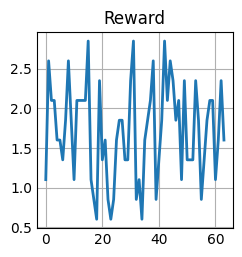

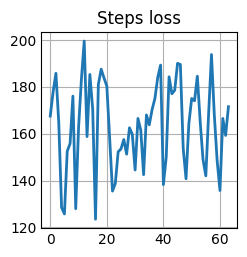

In [23]:
notebook_output_dir / "metrics.jsonl"